In [151]:
import socket, os

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

WORKING_DIR=f"{BASE_DIR}/data/tcga_xena"

os.chdir(WORKING_DIR)
print(f"📂 Working directory set to: {WORKING_DIR}")

📂 Working directory set to: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/data/tcga_xena


In [152]:
import pandas as pd
import numpy as np

In [61]:
expr = pd.read_csv(f"{WORKING_DIR}/data_ready/tcga_regression_ready_imputed.csv")

In [153]:
# Separate components
meta_cols = ["log_mut", "type", "cancer_type", "barcode"]
genes = [col for col in expr.columns if col not in meta_cols]


In [154]:
import seaborn as sns
import matplotlib.pyplot as plt


# Get all cancer types in consistent order
all_types = sorted(expr["cancer_type"].unique())

plt.rcParams['axes.prop_cycle'].by_key()['color']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

color_map = {
    ct: default_colors[i % len(default_colors)]
    for i, ct in enumerate(all_types)
}

In [155]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Option A: scale (recommended for structure visualization)
scaler = StandardScaler()
X_scaled_raw = scaler.fit_transform(expr[genes])

pca_raw = PCA(n_components=2)
pcs_raw = pca_raw.fit_transform(X_scaled_raw)

In [156]:
pcs_df = pd.DataFrame(
    pcs_raw,
    index=expr.index,   # IMPORTANT: keeps alignment
    columns=["PC1", "PC2"]
)

In [157]:
# Add metadata
pcs_df["cancer_type"] = expr["cancer_type"]
pcs_df["log_mut"] = expr["log_mut"]   # or whatever your column is


In [118]:
pcs_df

,PC1,PC2,cancer_type,logTMB,log_mut
0,-23.423952,-62.687318,ACC,1.531479,1.531479
1,-36.541316,0.851306,ACC,1.544068,1.544068
2,-24.921437,-47.760765,ACC,1.176091,1.176091
3,-24.732779,-78.996516,ACC,2.651278,2.651278
4,-20.135572,-60.984745,ACC,1.602060,1.602060
...,...,...,...,...,...
9099,32.003552,55.903213,STAD,2.545307,2.545307
9100,18.488941,52.078851,STAD,1.982271,1.982271
9101,2.963855,48.833954,STAD,1.806180,1.806180
9102,-9.518675,57.499780,STAD,2.123852,2.123852


In [ ]:
#pcs_df.to_csv(f"{BASE_DIR}/results/tables/tableS/pca_tmb_results_all_genes.csv",index=False)

In [158]:
from scipy.stats import pearsonr

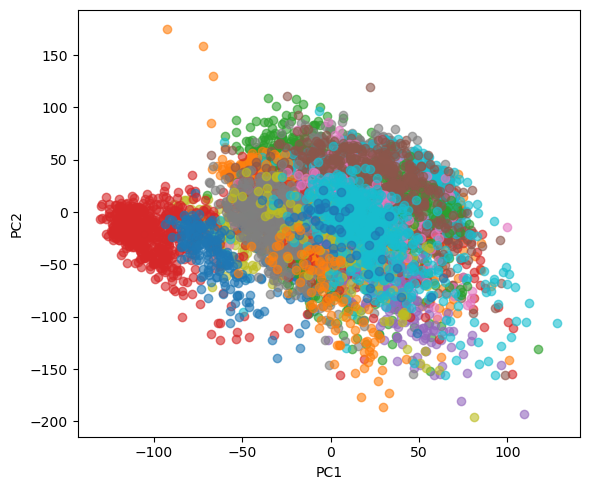

In [162]:
 
plt.figure(figsize=(6,5))

for ct in all_types:
    idx = expr["cancer_type"] == ct
    plt.scatter(
        pcs_raw[idx,0],
        pcs_raw[idx,1],
        label=ct,
        alpha=0.6,
        color=color_map[ct]
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
# plt.legend()
# plt.title("PCA without removing cancer type effect")
plt.tight_layout()
plt.show()

In [105]:
pcs_raw

array([[-23.42395212, -62.68731833],
       [-36.54131629,   0.85130605],
       [-24.92143739, -47.76076478],
       ...,
       [  2.96385485,  48.83395427],
       [ -9.51867537,  57.49977954],
       [ 14.67244223,  61.00916106]])

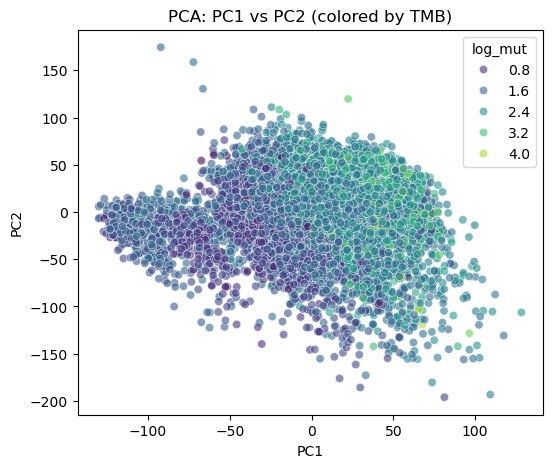

In [120]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))
sns.scatterplot(
    x=pcs_df["PC1"],   # PC1
    y=pcs_df["PC2"],   # PC2
    hue=pcs_df["log_mut"],
    palette="viridis",
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: PC1 vs PC2 (colored by TMB)")
plt.show()

In [135]:
tmb_weights = pd.read_csv(f"{BASE_DIR}/analysis/01_axis_analysis/bh/axes/tcga_tmb_genes_posBeta.tsv", sep="\t")

In [136]:
# Separate components
meta_cols = ["log_mut", "type", "cancer_type", "barcode"]
genes = tmb_weights["gene"]

In [137]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Option A: scale (recommended for structure visualization)
scaler = StandardScaler()
X_scaled_raw = scaler.fit_transform(expr[genes])

pca_raw = PCA(n_components=2)
pcs_raw = pca_raw.fit_transform(X_scaled_raw)

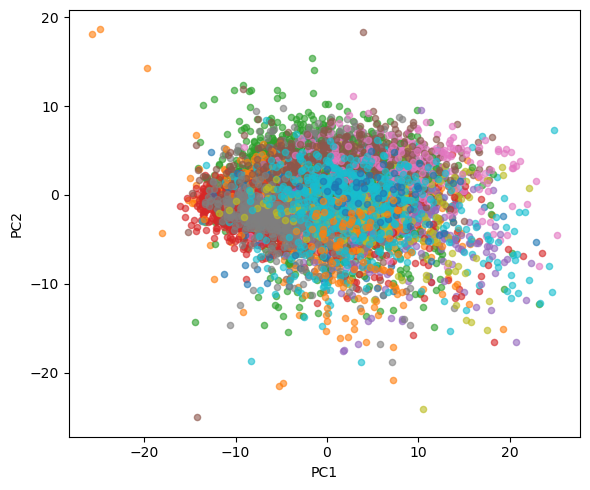

In [150]:
plt.figure(figsize=(6,5))

for ct in all_types:
    idx = expr["cancer_type"] == ct
    plt.scatter(
        pcs_raw[idx,0],
        pcs_raw[idx,1],
        label=ct,
        s=20,
        alpha=0.6,
        color=color_map[ct]
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
# plt.legend()
# plt.title("PCA without removing cancer type effect")
plt.tight_layout()
#plt.savefig(f"{BASE_DIR}/results/figures/main/fig3/pca_tmb_genes.pdf",dpi=300)
plt.show()

In [138]:
pqc_genes = pd.read_csv(f"{BASE_DIR}/data/corum/pqc_annotation.tsv",sep="\t")

In [139]:
pqc_genes.loc[pqc_genes["Hugo"]=="TOR4A", "Hugo"] = "C9orf167" # TOR4A = C9orf167 in tcga
pqc_genes.loc[pqc_genes["Hugo"]=="FAXC", "Hugo"] = "C6orf168"

In [140]:
axis_genes = set(tmb_weights["gene"])
pqc_gene_set = set(pqc_genes["Hugo"])
expr_genes = set(expr.columns)

In [141]:
axis_all = list(axis_genes & expr_genes)
pqc_axis_genes = list(axis_genes & pqc_gene_set & expr_genes)
non_pqc_genes = list((axis_genes - pqc_gene_set) & expr_genes)

In [142]:
expr[pqc_axis_genes]

,CLPX,MRPS12,HSPA4,MRPL16,MRPL41,MRPL39,PSMA6,PSMB2,MRPL48,MRPL24,...,MRPS24,CCT7,RPL8,VCP,MRPL3,MRPS18A,MRPL42,PSMC1,MRPL32,LONP1
0,-1.072451,-1.158885,-0.821231,1.654985,1.680210,1.532944,-0.439388,-0.578700,1.619637,1.009097,...,0.962205,1.153961,-0.597574,0.097400,-0.567057,0.334339,0.919088,0.488402,1.373599,3.455444
1,0.409912,-0.740391,-0.024007,0.243646,0.626920,-0.672707,-1.276146,-1.303321,0.241844,0.418644,...,1.218914,-1.383568,-0.597574,-0.450527,0.245733,-0.999485,1.751962,-1.926759,-0.949623,3.815724
2,-0.339597,1.109792,0.807879,0.513227,0.256845,2.843067,0.625577,-0.561447,-1.245546,-0.106202,...,1.133344,0.465484,-0.508017,-0.064949,-0.615824,-0.230575,1.474338,0.553677,1.984973,4.348939
3,-3.670749,0.603195,0.703893,0.988960,3.027662,0.289156,0.868997,-1.079034,-1.449083,-0.145566,...,0.306172,-1.049165,0.186048,0.787382,-1.688707,-1.956699,0.657795,-0.490717,1.722956,4.219238
4,1.309322,1.484234,0.859872,1.512266,0.873637,1.848037,0.108308,0.629001,0.774173,0.667946,...,1.917732,0.662192,-0.519211,1.010611,-1.867520,0.883560,1.196713,0.015161,1.373599,5.300080
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9099,1.409257,-0.255819,0.183964,0.449796,-0.748999,-0.208359,0.503866,0.801530,1.118621,-0.473595,...,0.092248,-0.518054,0.398746,-0.896986,0.522081,-0.638568,1.882609,-0.833409,1.426002,-1.040856
9100,0.609781,-0.167715,-0.283972,0.988960,-0.929292,1.665614,0.153949,0.490978,0.492352,-1.024683,...,0.206340,-0.301676,-0.452044,-0.430234,0.505826,-0.371803,2.094910,0.113073,1.251324,-0.132949
9101,0.276666,0.526104,0.478591,-0.089367,0.209400,-0.025937,0.914639,0.939553,0.257501,-0.316141,...,-0.250031,0.839229,-0.978190,-0.186711,0.278244,-0.528723,0.069884,-0.164344,1.478406,-1.069678
9102,1.176076,-1.224963,-0.197317,-0.025936,-0.805934,-0.224943,0.153949,0.025151,0.695889,-0.473595,...,-0.606571,-0.813116,-0.810271,-0.978161,0.180710,-0.136422,1.017074,-0.653904,0.814628,-1.660538


In [143]:
# Option A: scale (recommended for structure visualization)
scaler = StandardScaler()
X_scaled_raw = scaler.fit_transform(expr[pqc_axis_genes])

pca_raw = PCA(n_components=2)
pcs_raw = pca_raw.fit_transform(X_scaled_raw)

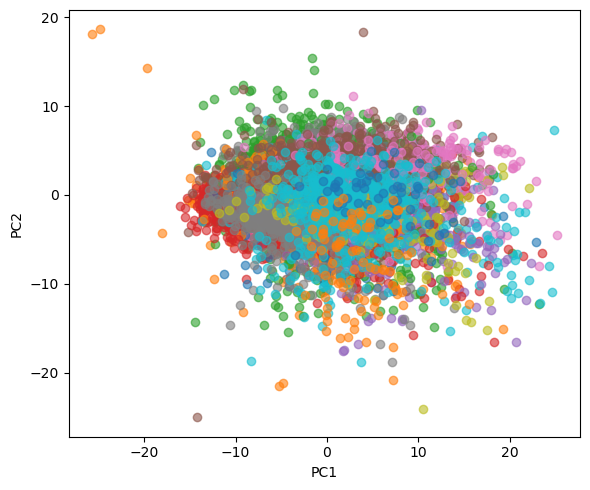

In [ ]:
plt.figure(figsize=(6,5))

for ct in all_types:
    idx = expr["cancer_type"] == ct
    plt.scatter(
        pcs_raw[idx,0],
        pcs_raw[idx,1],
        label=ct,
        alpha=0.6,
        color=color_map[ct]
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
# plt.legend()
plt.tight_layout()
# plt.savefig(f"{BASE_DIR}/results/figures/supplementary/pca_pqc_genes.pdf",dpi=300)
plt.show()

In [165]:
# Option A: scale (recommended for structure visualization)
scaler = StandardScaler()
X_scaled_raw = scaler.fit_transform(expr[non_pqc_genes])

pca_raw = PCA(n_components=2)
pcs_raw = pca_raw.fit_transform(X_scaled_raw)

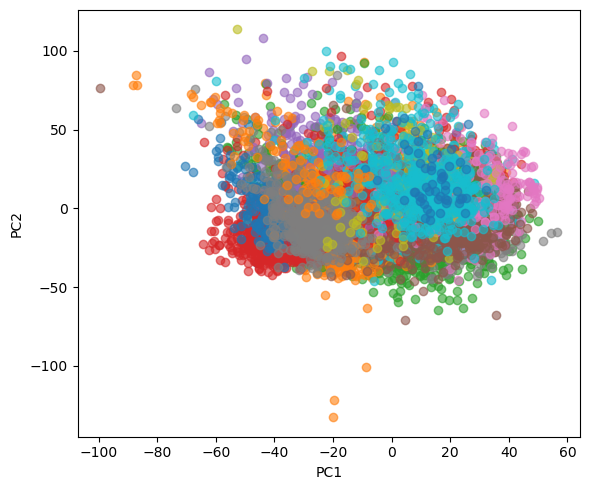

In [168]:
plt.figure(figsize=(6,5))

for ct in all_types:
    idx = expr["cancer_type"] == ct
    plt.scatter(
        pcs_raw[idx,0],
        pcs_raw[idx,1],
        label=ct,
        alpha=0.6,
        color=color_map[ct]
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
# plt.legend()
# plt.title("PCA without removing cancer type effect")
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/supplementary/pca_non_pqc_genes.pdf",dpi=300)
plt.show()